In [1]:
import pandas as pd
#%pip install seaborn
import seaborn as sns
#%pip install duckdb
#%pip install matplotlib
import duckdb
import matplotlib.pyplot as plt

In [2]:
olympics = pd.read_csv('data/olympics.csv')
olympics.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [3]:
#start by filtering the data
ath = duckdb.sql("""SELECT * FROM olympics
                        WHERE Games = '2016 Summer' AND SEX = 'M' 
                        AND (Sport = 'Basketball' OR Sport = 'Hockey' OR Sport = 'Gymnastics')""").df()
ath.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Individual All-Around,NaN
1,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Floor Exercise,NaN
2,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Parallel Bars,NaN
3,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Horizontal Bar,NaN
4,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Rings,NaN


<Axes: xlabel='Height', ylabel='Weight'>

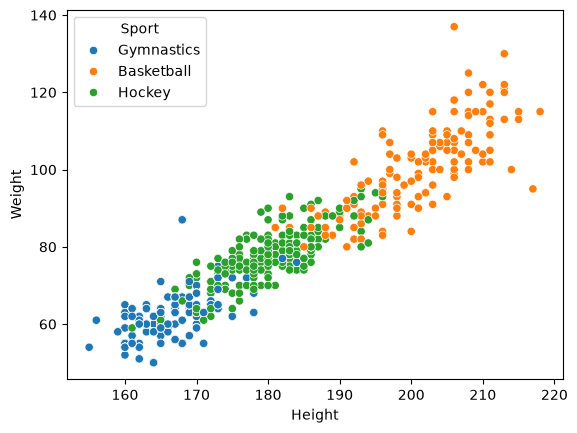

In [4]:
sns.scatterplot(ath, x='Height', y='Weight', hue='Sport')
#hue allows for grouping of subsets

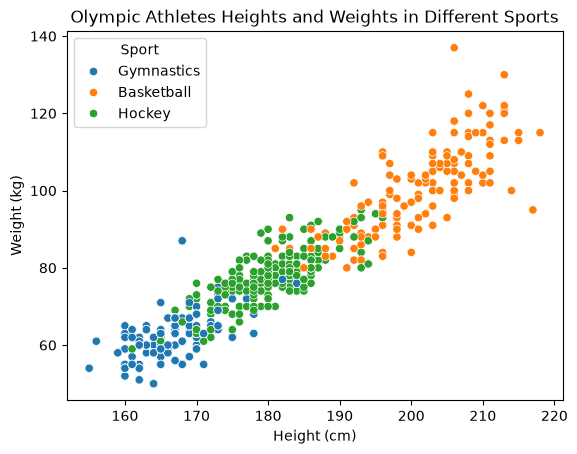

In [5]:
sns.scatterplot(ath, x='Height', y='Weight', hue='Sport')
plt.xlabel('Height (cm)') # label function from matplotlib
plt.ylabel('Weight (kg)')
plt.title('Olympic Athletes Heights and Weights in Different Sports')
plt.show()

In [6]:
#Line Plots
#manipulating out datasets
#to display data in line plot form

ath_line = duckdb.sql("""SELECT Year, AVG(Height) AS AvgHeight
                        FROM olympics
                        WHERE Season = 'Summer' AND Sport = 'Basketball'
                        GROUP BY Year
                        Order BY Year ASC""").df()
ath_line.head()

,Year,AvgHeight
0,1936,182.574074
1,1948,185.550725
2,1952,187.600000
3,1956,186.952941
4,1960,188.317708


<Axes: xlabel='Year', ylabel='AvgHeight'>

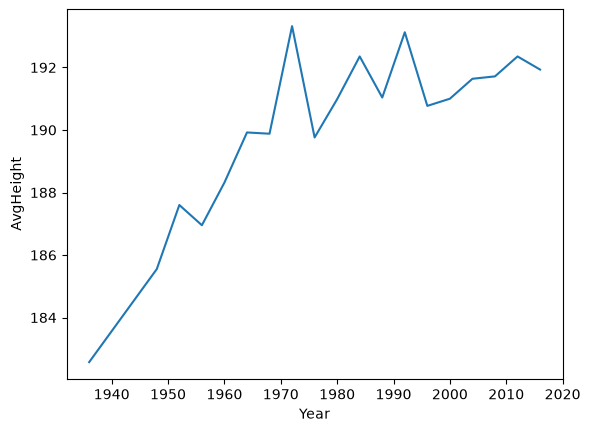

In [7]:
#graph using seaborn
sns.lineplot(ath_line, x='Year', y='AvgHeight')

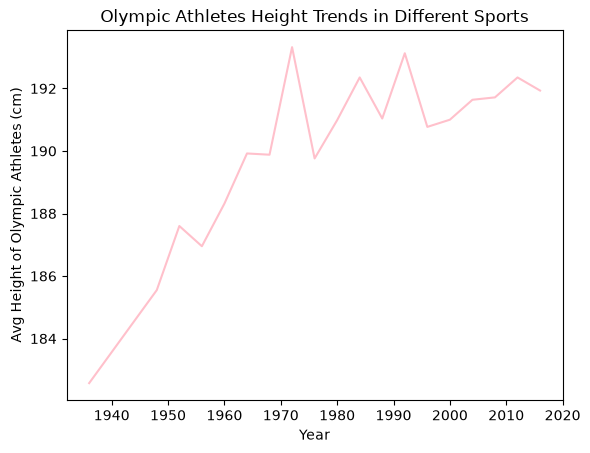

In [8]:
#A1
#duplicate the above plot, add an appropriate title, and approriate Y-acis albel
#change the color
sns.lineplot(ath_line, x='Year', y='AvgHeight', color = 'pink')
plt.xlabel('Year') # label function from matplotlib
plt.ylabel('Avg Height of Olympic Athletes (cm)')
plt.title('Olympic Athletes Height Trends in Different Sports')
plt.show()

In [9]:
#Create a histogram
#A2
golds = duckdb.sql("""SELECT Team, COUNT(*) AS Golds
                   FROM olympics 
                   WHERE Medal = 'Gold' AND Year = 2012
                   GROUP BY Team
                   ORDER BY Golds DESC
                   LIMIT 10""").df()
golds.head()

,Team,Golds
0,United States,139
1,Russia,50
2,China,50
3,Great Britain,46
4,Germany,43


<Axes: xlabel='Team', ylabel='Golds'>

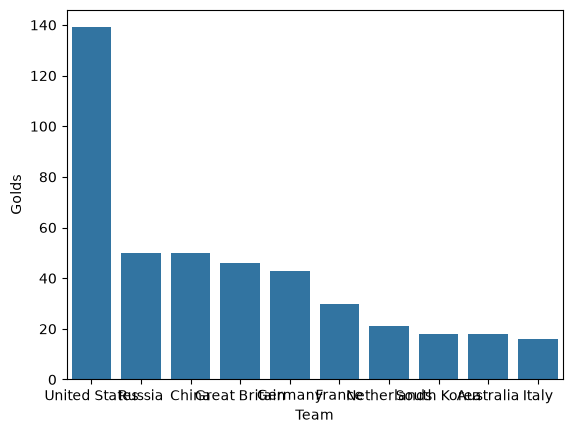

In [10]:
#call the barplot function in seaborn
sns.barplot(golds, x = 'Team', y = 'Golds')

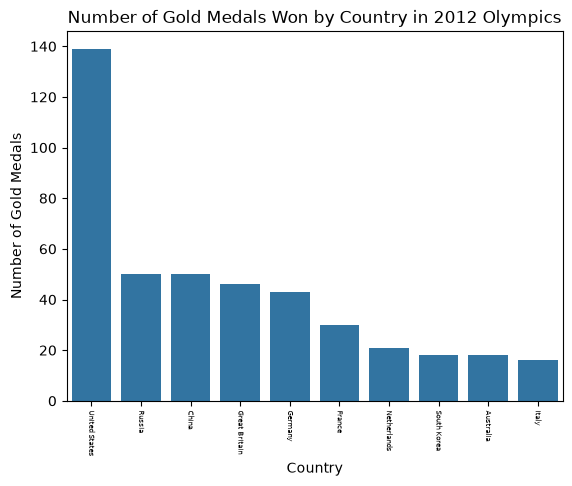

In [11]:
#all the labels are messed up
# improve
sns.barplot(golds, x = 'Team', y = 'Golds')
plt.xticks(rotation = -90, fontsize = 5)
plt.xlabel('Country')
plt.ylabel('Number of Gold Medals')
plt.title('Number of Gold Medals Won by Country in 2012 Olympics')
plt.show() 

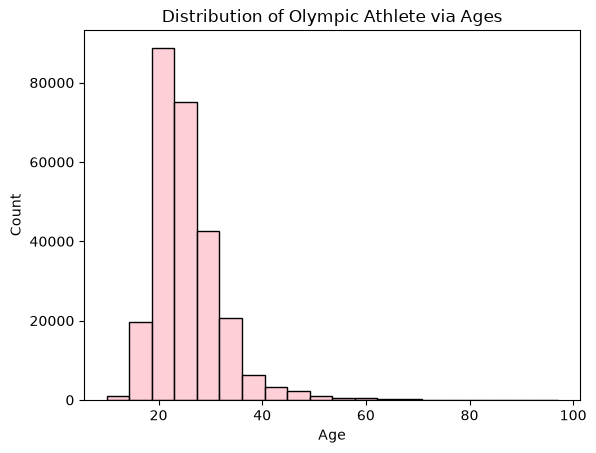

In [12]:
#We can also call a histogram function in seaborn
sns.histplot(olympics, x = 'Age', bins = 20, color = 'pink')
plt.title('Distribution of Olympic Athlete via Ages')
plt.show()



In [13]:
#A3
#filter the dataset to just be the 100 meter dash from the 2016 Summer Olympics
#make a scatterplot of each of the athletes hegihts(x-axis) and weight (y)
#use hue parameter to change the color of the points based on the medal cartgeory
#athletes = gold, silver, bronze
fastest = duckdb.sql("""SELECT * FROM olympics
                        WHERE Games = '2016 Summer' AND SEX = 'M' AND Event LIKE '% 100 metres%'
                        AND Sport = 'Athletics'""").df()
fastest['Medal'] = fastest['Medal'].fillna("")
fastest.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,611,Mohammed Abukhousa,M,23.0,170.0,67.0,Palestine,PLE,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 100 metres,
1,804,Antoine Xavier Adams,M,27.0,180.0,79.0,Saint Kitts and Nevis,SKN,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 100 metres,
2,804,Antoine Xavier Adams,M,27.0,180.0,79.0,Saint Kitts and Nevis,SKN,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 4 x 100 metres Relay,
3,1421,Masbah Ahmmed,M,21.0,NaN,NaN,Bangladesh,BAN,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 100 metres,
4,1488,Harry Leslie Aikines-Aryeetey,M,27.0,180.0,87.0,Great Britain,GBR,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 4 x 100 metres Relay,


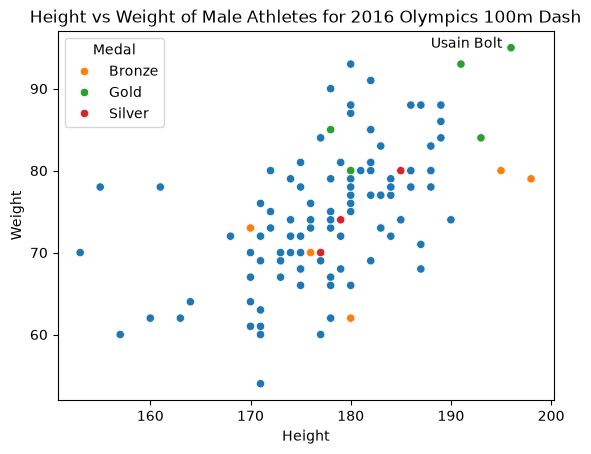

In [14]:
#Create the Scatterplot
#Use sns data = fastest
sns.scatterplot(fastest, x = 'Height', y = 'Weight', hue = 'Medal')
plt.annotate(text = "Usain Bolt", xy = (188, 95))
plt.title('Height vs Weight of Male Athletes for 2016 Olympics 100m Dash')
plt.show()

In [15]:
#Utilize Plotyly
#%pip install plotly
import plotly.express as px

In [16]:
#make a subset of the original olympics dataset and filter for 1992 summer gmes male athltest us team basketball
dream_team = duckdb.sql("""SELECT * FROM olympics
                          WHERE Games = '1992 Summer' AND SEX = 'M' AND Sport = 'Basketball' AND Team = 'United States'""").df( )
dream_team.head()


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,7901,Charles Wade Barkley,M,29.0,198.0,114.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
1,11668,Larry Joe Bird,M,35.0,205.0,100.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
2,30009,Clyde Austin Drexler,M,30.0,200.0,101.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
3,33553,Patrick Aloysius Ewing,M,29.0,213.0,109.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
4,55424,"Earvin ""Magic"" Johnson, Jr.",M,32.0,205.0,100.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold


In [17]:
#make the plotly plot
#%pip install --upgrade nbformat
fig = px.scatter(dream_team, x = 'Height', y = 'Weight', text = 'Name', width = 800, height = 500)
fig.update_layout(title = '1992 Dream Team Player Heights and Weights',
                  xaxis_title = 'Height (cm)',
                  yaxis_title = 'Weight (kg)')
fig.show()